*Previous notebook: exponentially weighted averages, gradient descent with momentum and Nesterov accelerated gradients. — This notebook: adaptive optimizers: AdaGrad, Adadelta, RMSProp, Adam, Adamax, AMSGrad and Nadam.*

### Setup

This notebook builds on **2.1**. The cell below re-runs `2.1_dataset_and_baseline.ipynb` silently to recreate the dataset, the normalised train/val/test splits and the network helpers (`init_params`, `forward`, `backward`, `update_params`, `mse`, `plot_loss`).

In [1]:
%%capture
%run "2.1_dataset_and_baseline.ipynb"

# Set Learning rate adaptively using AdaGrad 

In a nutshell, in AdaGrad, we set the learning rate to a small value when past gradients
value is high and to a high value when the past gradient value is less. So our learning rate
value changes according to the past gradients updates of the parameter.(Refer the section AdaGrad in the book for a detailed explanation)

The update equation of Adagrad is given as:


$${\theta_{t}^i = \theta_{t-1}^i - \dfrac{\eta}{\sqrt{ \sum_{\tau=1}^t (g_{\tau}^i)^2   + \epsilon}} \cdot g_{t}^i } $$

Final train MSE: 0.1568  |  val MSE: 0.1309  |  time: 2.71s


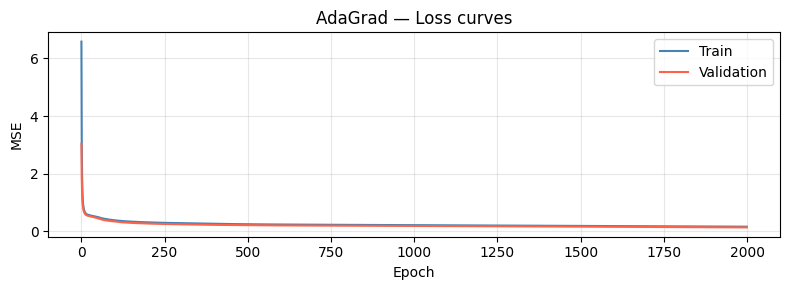

In [2]:
def adagrad(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epsilon=1e-8, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    grad_sq = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            grad_sq[key] += grads['d' + key] ** 2
            params[key]  -= lr * grads['d' + key] / (np.sqrt(grad_sq[key]) + epsilon)

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_ada, tl_ada, vl_ada, t_ada = adagrad(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, epsilon=1e-8, epochs=2000
)
plot_loss(tl_ada, vl_ada, title='AdaGrad — Loss curves')

# Do away with Learning rate using Adadelta 


With AdaDelta we completely get rid of learning rate. (Refer the section AdaDelta in the book for full explanation)

The update equation of AdaDelta is expressed as:

Running average of gradients:
$$E\left[g^{2}\right]_{t}=\gamma E\left[g^{2}\right]_{t-1}+(1-\gamma) g_{t}^{2} $$

Compute delta:
$$ \nabla \theta_{t}=-\frac{R M S[\Delta \theta]_{t-1}}{R M S\left[g_{t}\right]} \cdot g_{t}^{i} $$

Running averge of parameter update:
$$ E\left[\Delta \theta^{2}\right]_{t}=\gamma E\left[\Delta \theta^{2}\right]_{t-1}+(1-\gamma) \Delta \theta_{t}^{2} $$

Update theta:
$$ \theta_{t}^{i}=\theta_{t-1}^{i}+\nabla \theta_{t} $$

Final train MSE: 0.0664  |  val MSE: 0.0628  |  time: 3.07s


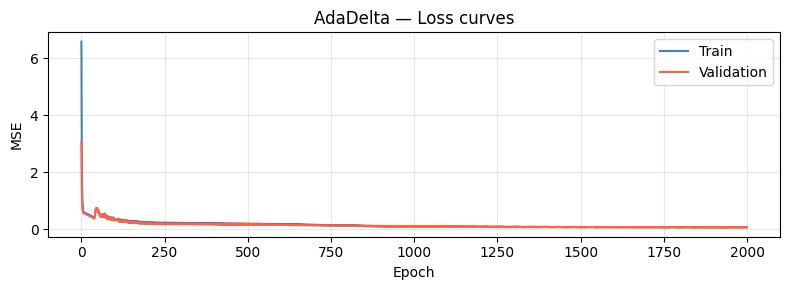

In [3]:
def adadelta(X_tr, y_tr, X_v, y_v, layer_sizes, gamma=0.9, epsilon=1e-5, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    E_grad2  = {key: np.zeros_like(val) for key, val in params.items()}
    E_delta2 = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g              = grads['d' + key]
            E_grad2[key]   = gamma * E_grad2[key] + (1 - gamma) * g ** 2
            delta          = -(np.sqrt(E_delta2[key] + epsilon)) / (np.sqrt(E_grad2[key] + epsilon)) * g
            E_delta2[key]  = gamma * E_delta2[key] + (1 - gamma) * delta ** 2
            params[key]   += delta

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_adad, tl_adad, vl_adad, t_adad = adadelta(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], gamma=0.9, epsilon=1e-5, epochs=2000
)
plot_loss(tl_adad, vl_adad, title='AdaDelta — Loss curves')

# Overcoming limitations of AdaGrad using RMSProp

We learned that in AdaGrad learning rate would become very small when the sum of gradients is high. So, we RMSProp to overcome the limitations of RMSProp. Stands for Root mean square prop. With RMSprop you can increase your learning rate.

The update equation of RMSProp is given as:

Running average of gradients:
$$E\left[g^{2}\right]_{t}=\gamma E\left[g^{2}\right]_{t-1}+(1-\gamma) g_{t}^{2} $$

Update theta:
$$\theta_{t}^{i}=\theta_{t-1}^{i}-\frac{\eta}{\sqrt{E\left[g^{2}\right]_{t}+\epsilon}} \cdot g_{t}^{i} $$

Final train MSE: 0.0541  |  val MSE: 0.0840  |  time: 2.92s


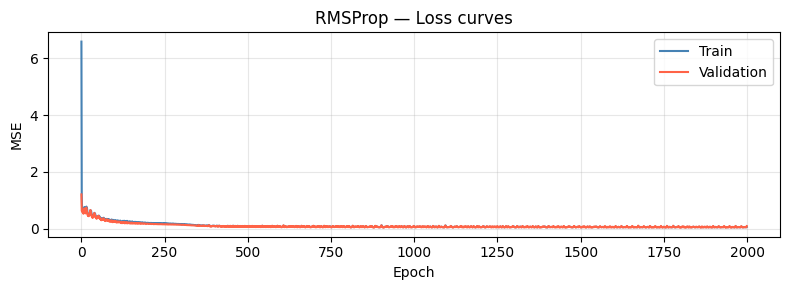

In [4]:
def rmsprop(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, gamma=0.9, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    E_grad2 = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for _ in range(epochs):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g             = grads['d' + key]
            E_grad2[key]  = gamma * E_grad2[key] + (1 - gamma) * g ** 2
            params[key]  -= lr / (np.sqrt(E_grad2[key]) + epsilon) * g

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_rms, tl_rms, vl_rms, t_rms = rmsprop(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, gamma=0.9, epsilon=1e-6, epochs=2000
)
plot_loss(tl_rms, vl_rms, title='RMSProp — Loss curves')

# Adam - Adaptive Moment Estimation

Adam optimization and RMSprop are among the optimization algorithms that worked very well with a lot of NN architectures. Adam optimization simply puts RMSprop and momentum together! The update equation of Adam is given as:

First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t} $$

Second moment estimate:
$$v_{t}=\beta_{2} v_{t-1}+\left(1-\beta_{2}\right) g_{t}^{2} $$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m_{t}}{1-\beta_{1}^{t}} $$

Bias-corrected vt:
$$\hat{v}_{t}=\frac{v_{t}}{1-\beta_{2}^{t}} $$

Update theta:

$$\theta_{t}=\theta_{t-1}-\frac{\eta}{\sqrt{\hat{v}_{t}}+\epsilon} \hat{m}_{t} $$

Hyperparameters for Adam:
- $\eta$: needed to be tuned.
- $\beta_1$: parameter of the momentum - 0.9 is recommended by default.
- $\beta_2$: parameter of the RMSprop - 0.999 is recommended by default.
- $\epsilon$: 10^-8 is recommended by default.

Final train MSE: 0.0408  |  val MSE: 0.0392  |  time: 3.06s


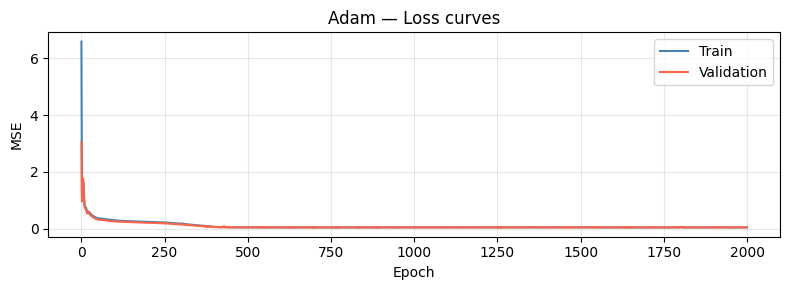

In [5]:
def adam(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt = {key: np.zeros_like(val) for key, val in params.items()}
    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g       = grads['d' + key]
            mt[key] = beta1 * mt[key] + (1 - beta1) * g
            vt[key] = beta2 * vt[key] + (1 - beta2) * g ** 2
            mt_hat  = mt[key] / (1 - beta1 ** t)
            vt_hat  = vt[key] / (1 - beta2 ** t)
            params[key] -= lr / (np.sqrt(vt_hat) + epsilon) * mt_hat

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_adam, tl_adam, vl_adam, t_adam = adam(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_adam, vl_adam, title='Adam — Loss curves')

# Adamax - Adam based on infinity norm


Check the section Adamax in the book for the detailed explanation. The update equation of Adamax is given as:

First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t} $$

Second moment estimate:
$$v_{t}=\max \left(\beta_{2} \cdot v_{t-1},\left|g_{t}\right|\right) $$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m_{t}}{1-\beta_{1}^{t}} $$

Update theta:

$$\theta_{t}=\theta_{t-1}-\frac{\eta}{v_{t}} \hat{m}_{t} $$


Final train MSE: 0.0379  |  val MSE: 0.0362  |  time: 3.26s


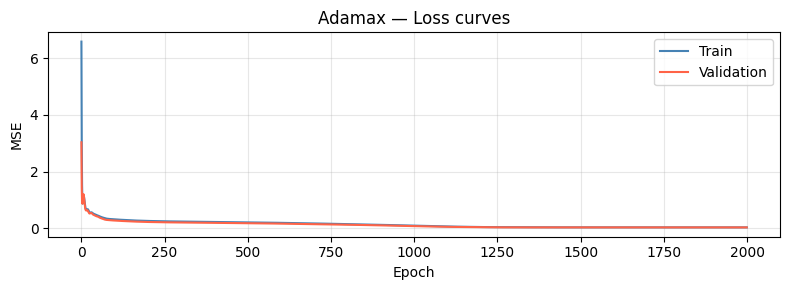

In [6]:
def adamax(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt = {key: np.zeros_like(val) for key, val in params.items()}
    vt = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g       = grads['d' + key]
            mt[key] = beta1 * mt[key] + (1 - beta1) * g
            mt_hat  = mt[key] / (1 - beta1 ** t)
            vt[key] = np.maximum(beta2 * vt[key], np.abs(g))
            params[key] -= (lr / (vt[key] + epsilon)) * mt_hat

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_amax, tl_amax, vl_amax, t_amax = adamax(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_amax, vl_amax, title='Adamax — Loss curves')

# Adaptive Moment Estimation with AMSGrad


Refer the section AMSGrad in the book for the detailed explanation. The update equation of AMSGrad is given as:

First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t} $$

Second moment estimate:
$$v_{t}=\beta_{2} v_{t-1}+\left(1-\beta_{2}\right) g_{t}^{2} $$

Updated second moment estimate:
$$\hat{v}_{t}=\max \left(\hat{v}_{t-1}, v_{t}\right)$$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m t}{1-\beta_{1}^{t}} $$

Update theta:
$$\theta_{t}=\theta_{t-1}-\frac{\eta}{\sqrt{\hat{v}_{t}}+\epsilon} \hat{m}_{t} $$

Final train MSE: 0.0500  |  val MSE: 0.0441  |  time: 3.05s


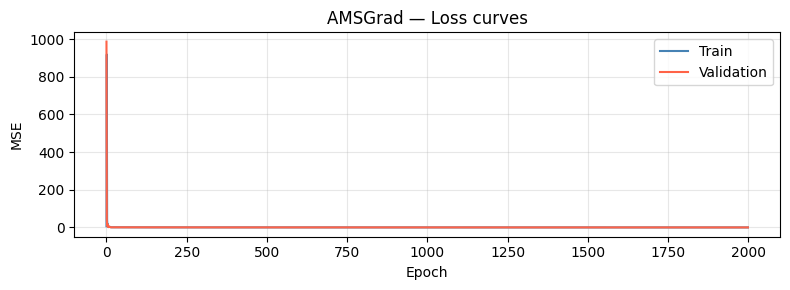

In [7]:
def amsgrad(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt     = {key: np.zeros_like(val) for key, val in params.items()}
    vt     = {key: np.zeros_like(val) for key, val in params.items()}
    vt_hat = {key: np.zeros_like(val) for key, val in params.items()}

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        for key in params:
            g           = grads['d' + key]
            mt[key]     = beta1 * mt[key] + (1 - beta1) * g
            vt[key]     = beta2 * vt[key] + (1 - beta2) * g ** 2
            vt_hat[key] = np.maximum(vt_hat[key], vt[key])
            mt_hat      = mt[key] / (1 - beta1 ** t)
            params[key] -= lr / (np.sqrt(vt_hat[key]) + epsilon) * mt_hat

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_ams, tl_ams, vl_ams, t_ams = amsgrad(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_ams, vl_ams, title='AMSGrad — Loss curves')

# Nadam - Adding NAG to ADAM


Refer the section Nadam in the book for the detailed explanation. The update equation of Nadam is given as:


First moment estimate:
$$m_{t}=\beta_{1} m_{t-1}+\left(1-\beta_{1}\right) g_{t}  $$

Second moment estimate:
$$v_{t}=\beta_{2} v_{t-1}+\left(1-\beta_{2}\right) g_{t}^{2} $$

Bias-corrected mt:
$$\hat{m}_{t}=\frac{m_{t}}{1-\prod_{i=1}^{t+1} \beta_{1}^{i}}  $$

Bias-corrected gt:
$$\hat{g}_{t}=\frac{g_{t}}{1-\prod_{i=1}^{t} \beta_{1}^{i}} $$

Bias-corrected vt:
$$ \hat{v}_{t}=\frac{v_{t}}{1-\beta_{2}^{t}} $$

Compute m tilde:
$$ \tilde{m}_{t}=\beta_{1}^{t+1} \hat{m}_{t}+\left(1-\beta_{1}^{t}\right) \hat{g}_{t} $$

Update theta:
$$ \theta_{t}=\theta_{t-1}-\frac{\eta}{\sqrt{v_{t}}+\epsilon} \tilde{m}_{t}  $$

Final train MSE: 0.0419  |  val MSE: 0.0451  |  time: 3.02s


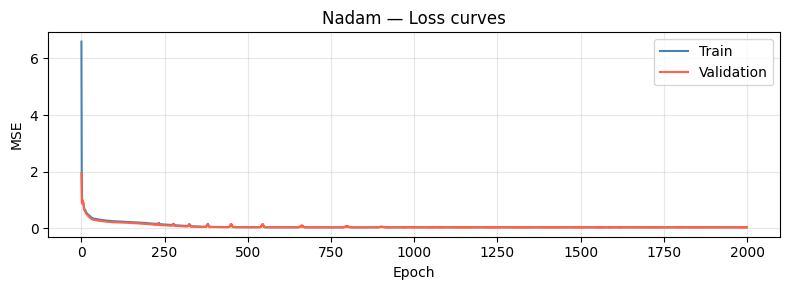

In [8]:
def nadam(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []

    mt         = {key: np.zeros_like(val) for key, val in params.items()}
    vt         = {key: np.zeros_like(val) for key, val in params.items()}
    beta1_prod = 1.0

    start = time.time()
    for t in range(1, epochs + 1):
        y_hat, cache = forward(X_tr, params)
        grads        = backward(y_tr, y_hat, params, cache)

        beta1_prod *= beta1

        for key in params:
            g        = grads['d' + key]
            mt[key]  = beta1 * mt[key] + (1 - beta1) * g
            vt[key]  = beta2 * vt[key] + (1 - beta2) * g ** 2
            mt_hat   = mt[key] / (1 - beta1_prod * beta1)
            g_hat    = g       / (1 - beta1_prod)
            vt_hat   = vt[key] / (1 - beta2 ** t)
            mt_tilde = beta1 * mt_hat + (1 - beta1) * g_hat
            params[key] -= lr / (np.sqrt(vt_hat) + epsilon) * mt_tilde

        train_loss.append(mse(y_tr, y_hat))
        y_hat_v, _ = forward(X_v, params)
        val_loss.append(mse(y_v, y_hat_v))
    end = time.time()

    elapsed = end - start
    print(f'Final train MSE: {train_loss[-1]:.4f}  |  val MSE: {val_loss[-1]:.4f}  |  time: {elapsed:.2f}s')
    return params, train_loss, val_loss, elapsed

params_nadam, tl_nadam, vl_nadam, t_nadam = nadam(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1], lr=1e-2, beta1=0.9, beta2=0.999, epsilon=1e-6, epochs=2000
)
plot_loss(tl_nadam, vl_nadam, title='Nadam — Loss curves')